# Machine Learning Lab Task — Part 1: Regression

**Dataset:** Salary Prediction Data (Kaggle) — `datasets/salary_data.csv`

**Goal:** Predict an employee's `Salary` using

1. **Simple Linear Regression** — one input feature (`Experience`)
2. **Multiple Linear Regression** — all available features (`Education`, `Experience`, `Location`, `Job_Title`, `Age`, `Gender`)

**Steps:** load data → explore (EDA) → preprocess → train/test split → train model → evaluate → visualize → compare

## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

## 2. Load the Dataset

In [2]:
df = pd.read_csv("../datasets/salary_data.csv")
print("Shape of dataset:", df.shape)
df.head()

Shape of dataset: (1000, 7)


,Education,Experience,Location,Job_Title,Age,Gender,Salary
0,High School,8,Urban,Manager,63,Male,84620.053665
1,PhD,11,Suburban,Director,59,Male,142591.255894
2,Bachelor,28,Suburban,Manager,61,Female,97800.255404
3,High School,29,Rural,Director,45,Male,96834.671282
4,PhD,25,Urban,Analyst,26,Female,132157.786175


## 3. Exploratory Data Analysis (EDA)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Education   1000 non-null   str    
 1   Experience  1000 non-null   int64  
 2   Location    1000 non-null   str    
 3   Job_Title   1000 non-null   str    
 4   Age         1000 non-null   int64  
 5   Gender      1000 non-null   str    
 6   Salary      1000 non-null   float64
dtypes: float64(1), int64(2), str(4)
memory usage: 54.8 KB


In [4]:
df.describe()

,Experience,Age,Salary
count,1000.000000,1000.000000,1000.000000
mean,14.771000,42.377000,105558.404239
std,8.341111,13.609412,28256.972075
min,1.000000,20.000000,33510.510669
25%,7.000000,30.000000,85032.141517
50%,15.000000,43.000000,104314.518315
75%,22.000000,55.000000,126804.047524
max,29.000000,64.000000,193016.602150


In [5]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Missing values per column:
Education     0
Experience    0
Location      0
Job_Title     0
Age           0
Gender        0
Salary        0
dtype: int64

Duplicate rows: 0


In [6]:
# Categorical columns: unique values
for col in ["Education", "Location", "Job_Title", "Gender"]:
    print(f"{col:10s} ->", df[col].unique().tolist())

Education  -> ['High School', 'PhD', 'Bachelor', 'Master']
Location   -> ['Urban', 'Suburban', 'Rural']
Job_Title  -> ['Manager', 'Director', 'Analyst', 'Engineer']
Gender     -> ['Male', 'Female']


### 3.1 Distribution of the target (`Salary`)

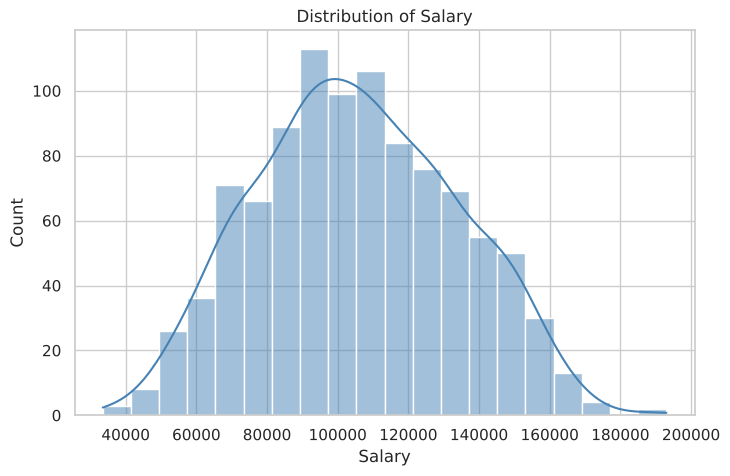

In [7]:
sns.histplot(df["Salary"], kde=True, color="steelblue")
plt.title("Distribution of Salary")
plt.xlabel("Salary")
plt.show()

### 3.2 Correlation between numeric features

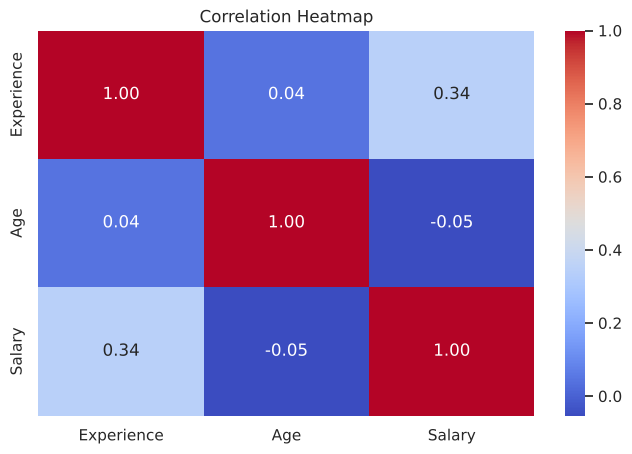

In [8]:
corr = df[["Experience", "Age", "Salary"]].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

`Experience` has the strongest relationship with `Salary`, so it is a natural choice for Simple Linear Regression.

### 3.3 Salary vs categorical features

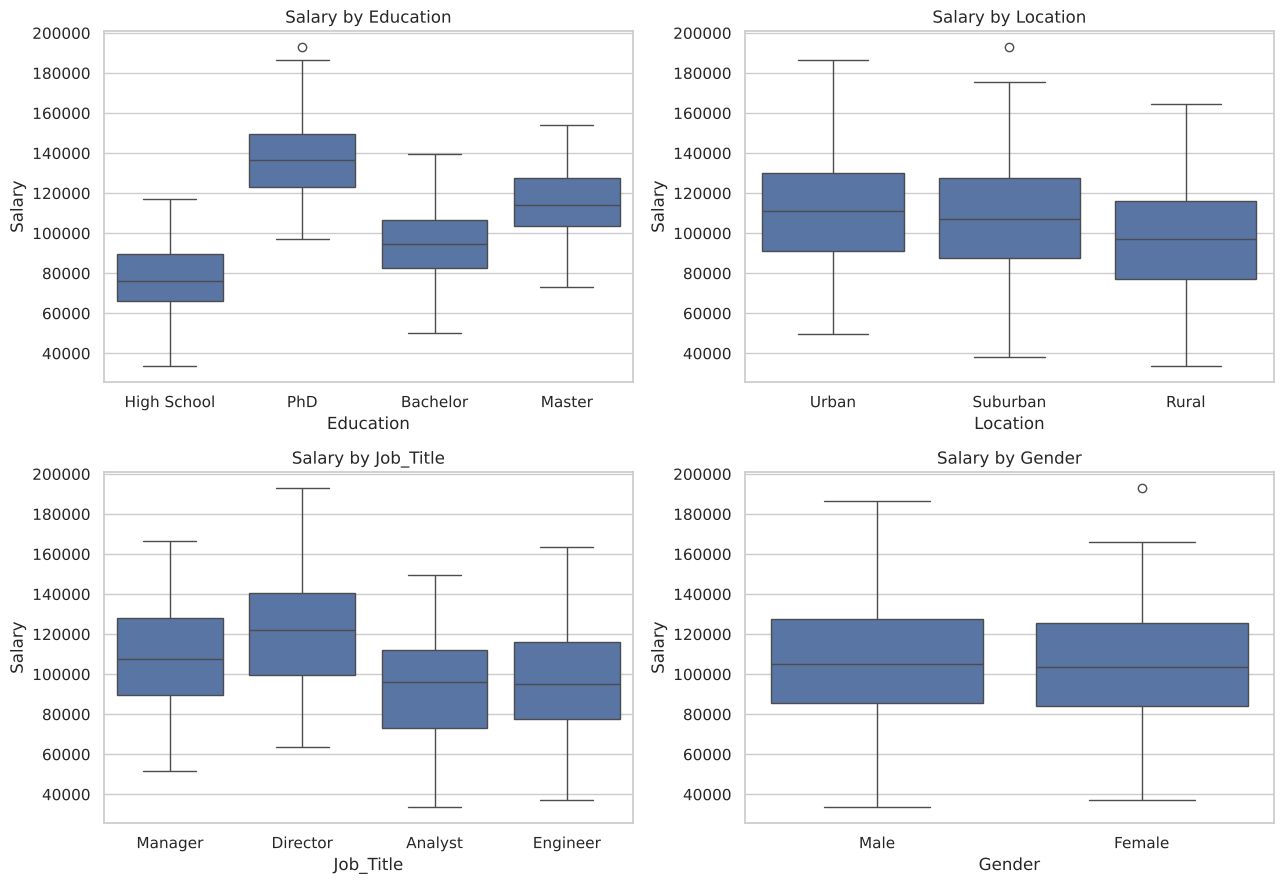

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, col in zip(axes.ravel(), ["Education", "Location", "Job_Title", "Gender"]):
    sns.boxplot(data=df, x=col, y="Salary", ax=ax)
    ax.set_title(f"Salary by {col}")
plt.tight_layout()
plt.show()

---
# Part A — Simple Linear Regression

Simple Linear Regression models the relationship between **one** independent variable (X) and the dependent variable (y):

$$y = \beta_0 + \beta_1 x$$

- **X** = `Experience` (years)
- **y** = `Salary`

### A.1 Select Feature and Target

In [10]:
X_simple = df[["Experience"]]   # 2D (DataFrame) because sklearn expects 2D input
y = df["Salary"]

X_simple.head()

,Experience
0,8
1,11
2,28
3,29
4,25


### A.2 Train / Test Split (80% / 20%)

In [11]:
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_simple, y, test_size=0.2, random_state=42
)
print("Training samples:", X_train_s.shape[0])
print("Testing samples :", X_test_s.shape[0])

Training samples: 800
Testing samples : 200


### A.3 Train the Model

In [12]:
slr = LinearRegression()
slr.fit(X_train_s, y_train_s)

print("Intercept (β0):", round(slr.intercept_, 2))
print("Slope (β1)    :", round(slr.coef_[0], 2))
print(f"\nEquation: Salary = {slr.intercept_:.2f} + {slr.coef_[0]:.2f} × Experience")

Intercept (β0): 89488.92
Slope (β1)    : 1078.52

Equation: Salary = 89488.92 + 1078.52 × Experience


**Interpretation:** for every additional year of experience, the predicted salary changes by the slope value (β1).

### A.4 Predictions

In [13]:
y_pred_s = slr.predict(X_test_s)

results_s = pd.DataFrame({
    "Experience": X_test_s["Experience"].values,
    "Actual Salary": y_test_s.values,
    "Predicted Salary": y_pred_s
}).round(2)
results_s.head(10)

,Experience,Actual Salary,Predicted Salary
0,13,86677.84,103509.69
1,6,56036.16,95960.04
2,16,92226.87,106745.26
3,5,100710.09,94881.52
4,26,91775.01,117530.47
5,3,52282.49,92724.48
6,1,102139.81,90567.44
7,9,127491.15,99195.61
8,23,117342.19,114294.90
9,7,99647.04,97038.56


### A.5 Evaluation

In [14]:
def evaluate(y_true, y_pred, name):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    print(f"--- {name} ---")
    print(f"MAE  : {mae:,.2f}")
    print(f"MSE  : {mse:,.2f}")
    print(f"RMSE : {rmse:,.2f}")
    print(f"R²   : {r2:.4f}")
    return {"Model": name, "MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2}

metrics_simple = evaluate(y_test_s, y_pred_s, "Simple Linear Regression")

--- Simple Linear Regression ---
MAE  : 21,585.39
MSE  : 675,798,552.71
RMSE : 25,996.13
R²   : 0.1723


### A.6 Visualization

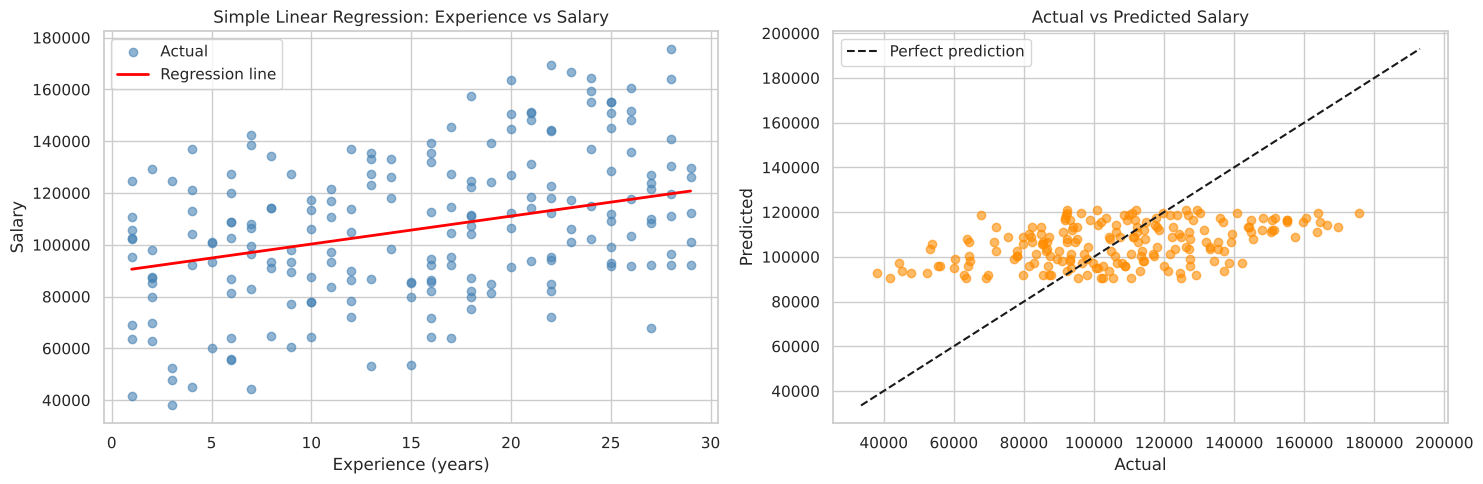

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Regression line on test data
axes[0].scatter(X_test_s, y_test_s, color="steelblue", alpha=0.6, label="Actual")
line_x = np.linspace(X_simple.min(), X_simple.max(), 100).reshape(-1, 1)
axes[0].plot(line_x, slr.predict(pd.DataFrame(line_x, columns=["Experience"])),
             color="red", linewidth=2, label="Regression line")
axes[0].set_title("Simple Linear Regression: Experience vs Salary")
axes[0].set_xlabel("Experience (years)")
axes[0].set_ylabel("Salary")
axes[0].legend()

# Actual vs Predicted
axes[1].scatter(y_test_s, y_pred_s, color="darkorange", alpha=0.6)
axes[1].plot([y.min(), y.max()], [y.min(), y.max()], "k--", label="Perfect prediction")
axes[1].set_title("Actual vs Predicted Salary")
axes[1].set_xlabel("Actual")
axes[1].set_ylabel("Predicted")
axes[1].legend()

plt.tight_layout()
plt.show()

### A.7 Predict for a New Value

In [16]:
new_exp = pd.DataFrame({"Experience": [5, 10, 20]})
for e, p in zip(new_exp["Experience"], slr.predict(new_exp)):
    print(f"Experience = {e:2d} years  ->  Predicted Salary = {p:,.2f}")

Experience =  5 years  ->  Predicted Salary = 94,881.52
Experience = 10 years  ->  Predicted Salary = 100,274.13
Experience = 20 years  ->  Predicted Salary = 111,059.34


---
# Part B — Multiple Linear Regression

Multiple Linear Regression uses **two or more** independent variables:

$$y = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_n x_n$$

Because the dataset has categorical columns (`Education`, `Location`, `Job_Title`, `Gender`), they must be converted to numbers first using **One-Hot Encoding**.

### B.1 Preprocessing — Encode Categorical Variables

In [17]:
X_multi = df.drop("Salary", axis=1)

# One-hot encoding; drop_first=True avoids the dummy variable trap (multicollinearity)
X_multi = pd.get_dummies(X_multi, columns=["Education", "Location", "Job_Title", "Gender"], drop_first=True)

print("Shape after encoding:", X_multi.shape)
X_multi.head()

Shape after encoding: (1000, 11)


,Experience,Age,Education_High School,Education_Master,Education_PhD,Location_Suburban,Location_Urban,Job_Title_Director,Job_Title_Engineer,Job_Title_Manager,Gender_Male
0,8,63,True,False,False,False,True,False,False,True,True
1,11,59,False,False,True,True,False,True,False,False,True
2,28,61,False,False,False,True,False,False,False,True,False
3,29,45,True,False,False,False,False,True,False,False,True
4,25,26,False,False,True,False,True,False,False,False,False


### B.2 Train / Test Split (80% / 20%)

In [18]:
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_multi, y, test_size=0.2, random_state=42
)
print("Training samples:", X_train_m.shape[0])
print("Testing samples :", X_test_m.shape[0])

Training samples: 800
Testing samples : 200


### B.3 Train the Model

In [19]:
mlr = LinearRegression()
mlr.fit(X_train_m, y_train_m)

print("Intercept (β0):", round(mlr.intercept_, 2))

Intercept (β0): 62899.24


In [20]:
coef_df = pd.DataFrame({
    "Feature": X_multi.columns,
    "Coefficient": mlr.coef_
}).sort_values("Coefficient", ascending=False).reset_index(drop=True)
coef_df.round(2)

,Feature,Coefficient
0,Education_PhD,40306.36
1,Job_Title_Director,25106.58
2,Education_Master,21105.77
3,Job_Title_Manager,15284.96
4,Location_Urban,9920.74
5,Location_Suburban,4839.29
6,Job_Title_Engineer,3979.18
7,Experience,1002.18
8,Gender_Male,503.42
9,Age,10.00


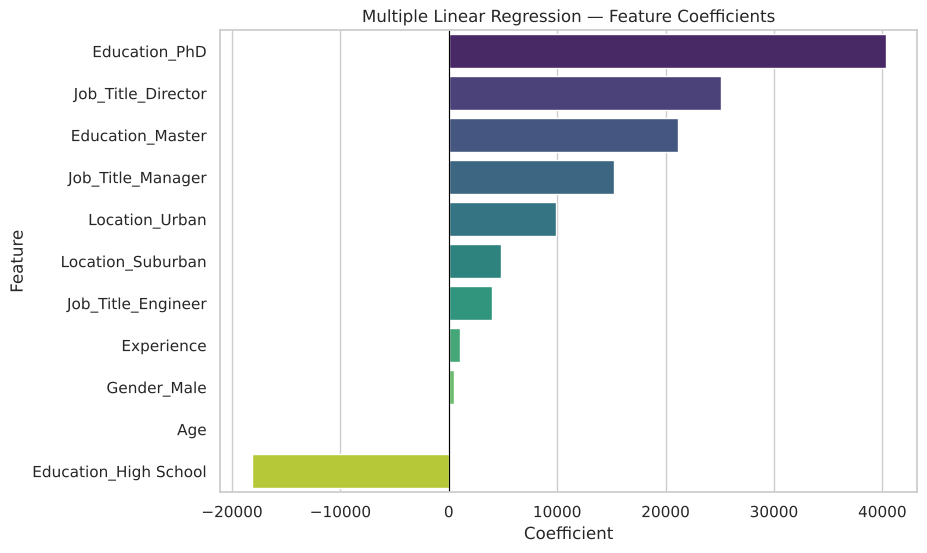

In [21]:
plt.figure(figsize=(9, 6))
sns.barplot(data=coef_df, x="Coefficient", y="Feature", palette="viridis")
plt.title("Multiple Linear Regression — Feature Coefficients")
plt.axvline(0, color="black", linewidth=0.8)
plt.show()

**Interpretation:** a positive coefficient means the feature increases salary (holding other features constant); a negative one means it decreases salary relative to the dropped baseline category.

### B.4 Predictions

In [22]:
y_pred_m = mlr.predict(X_test_m)

results_m = pd.DataFrame({
    "Actual Salary": y_test_m.values,
    "Predicted Salary": y_pred_m
}).round(2)
results_m["Error"] = (results_m["Actual Salary"] - results_m["Predicted Salary"]).round(2)
results_m.head(10)

,Actual Salary,Predicted Salary,Error
0,86677.84,80980.43,5697.41
1,56036.16,56651.22,-615.06
2,92226.87,110570.89,-18344.02
3,100710.09,98116.12,2593.97
4,91775.01,93708.61,-1933.60
5,52282.49,66619.30,-14336.81
6,102139.81,94437.57,7702.24
7,127491.15,118178.21,9312.94
8,117342.19,121395.24,-4053.05
9,99647.04,106625.37,-6978.33


### B.5 Evaluation

In [23]:
metrics_multi = evaluate(y_test_m, y_pred_m, "Multiple Linear Regression")

--- Multiple Linear Regression ---
MAE  : 8,157.90
MSE  : 105,996,277.66
RMSE : 10,295.45
R²   : 0.8702


### B.6 Visualization

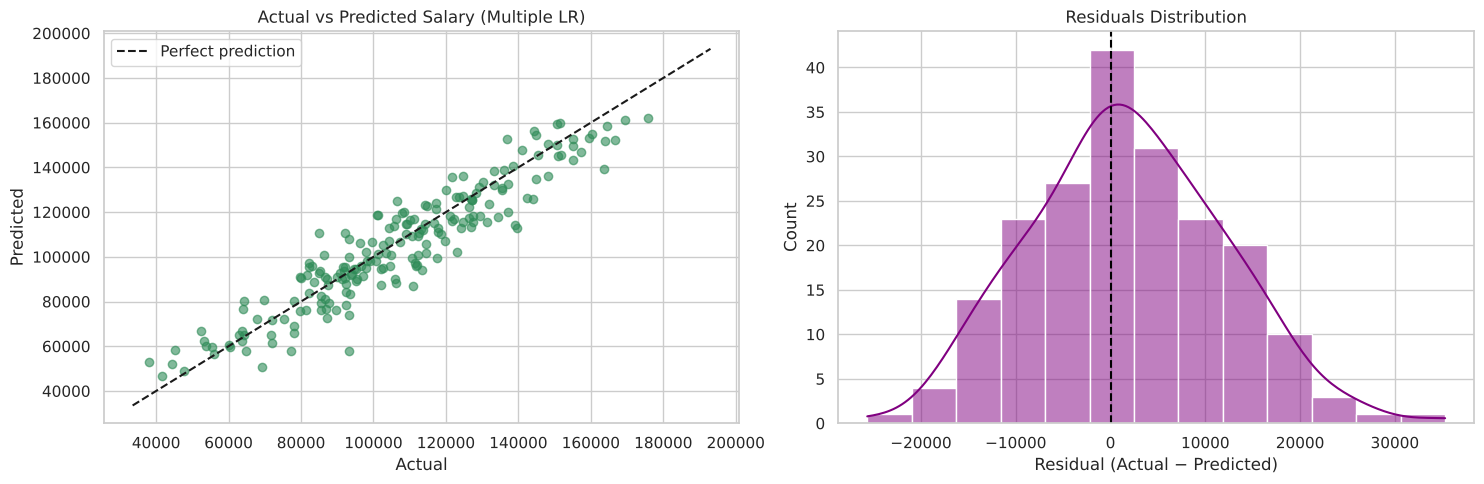

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].scatter(y_test_m, y_pred_m, color="seagreen", alpha=0.6)
axes[0].plot([y.min(), y.max()], [y.min(), y.max()], "k--", label="Perfect prediction")
axes[0].set_title("Actual vs Predicted Salary (Multiple LR)")
axes[0].set_xlabel("Actual")
axes[0].set_ylabel("Predicted")
axes[0].legend()

residuals = y_test_m - y_pred_m
sns.histplot(residuals, kde=True, color="purple", ax=axes[1])
axes[1].axvline(0, color="black", linestyle="--")
axes[1].set_title("Residuals Distribution")
axes[1].set_xlabel("Residual (Actual − Predicted)")

plt.tight_layout()
plt.show()

A good model has predictions close to the diagonal line and residuals that are roughly bell-shaped and centred around zero.

### B.7 Predict for a New Employee

In [25]:
new_employee = pd.DataFrame([{
    "Education": "Master", "Experience": 8, "Location": "Urban",
    "Job_Title": "Engineer", "Age": 32, "Gender": "Male"
}])

# Apply the same encoding and align columns with the training data
new_encoded = pd.get_dummies(new_employee, columns=["Education", "Location", "Job_Title", "Gender"])
new_encoded = new_encoded.reindex(columns=X_multi.columns, fill_value=0)

print(f"Predicted Salary: {mlr.predict(new_encoded)[0]:,.2f}")

Predicted Salary: 106,745.93


---
# Part C — Comparison of Both Models

In [26]:
comparison = pd.DataFrame([metrics_simple, metrics_multi]).set_index("Model")
comparison.round(4)

,MAE,MSE,RMSE,R2
Model,,,,
Simple Linear Regression,21585.3938,6.757986e+08,25996.1257,0.1723
Multiple Linear Regression,8157.8985,1.059963e+08,10295.4494,0.8702


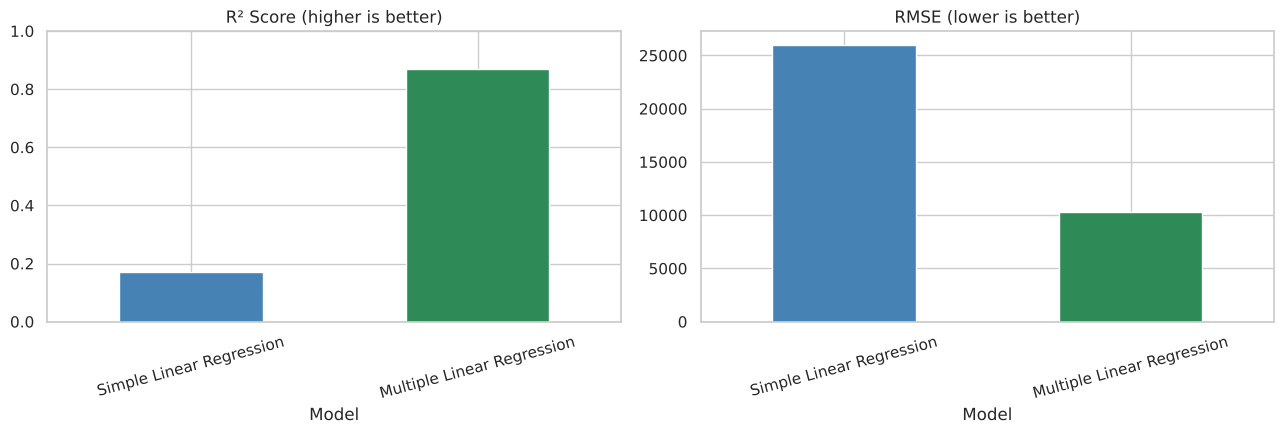

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

comparison["R2"].plot(kind="bar", ax=axes[0], color=["steelblue", "seagreen"], rot=15)
axes[0].set_title("R² Score (higher is better)")
axes[0].set_ylim(0, 1)

comparison["RMSE"].plot(kind="bar", ax=axes[1], color=["steelblue", "seagreen"], rot=15)
axes[1].set_title("RMSE (lower is better)")

plt.tight_layout()
plt.show()

## Conclusion

- **Simple Linear Regression** uses only `Experience`. It is easy to interpret and visualize but ignores the other information available.
- **Multiple Linear Regression** uses all features, so it captures the effect of education, job title, location, etc., and gives a higher R² and lower error.
- Since the multiple regression model explains more of the variance in salary, it is the better model for this dataset.